In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

from pprint import pprint

from functools import partial

import numpy as np
from sklearn.preprocessing import scale
# import sklearn.metrics as metrics
from sklearn.metrics import accuracy_score, confusion_matrix

import matplotlib.pyplot as plt
import matplotlib.animation as ani

import mlgrad.models as models
import mlgrad.regr as regr
import mlgrad.cls as cls
import mlgrad.pca as pca
import mlgrad.plots as plots
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss
import mlgrad.gd as gd
import mlgrad.smooth as smooth
import mlgrad.inventory as inventory
from mlgrad.af import averaging_function
import mlgrad.avragg as avragg

import rampy
import pybaselines
import random

from irsa import io
from irsa.preprocess import despike, utils
import irsa.widgets as widgets
import irsa.spectra as spectra
import irsa.io as io

import scipy.special as special

import copy

import ipywidgets
from IPython.display import display

import sys
import os
print(sys.version)

# %matplotlib widget

3.13.12 (main, Feb  4 2026, 15:06:39) [GCC 15.2.0]


In [2]:
OP1 = ["29", "37", "39"]
OP2 = ["33", "34", "36", "38", "41"]
root = "/home/intellimath/YD/repos/spectra/tears"
d1 = {}
d2 = {}

xx1 = []
xx2 = []
for entry in os.scandir(root):
    if not entry.is_dir():
        continue
    key = entry.name[:2]
    key2 = entry.name[:5]
    if key not in OP1 and key not in OP2:
        continue
    # print(entry.name)
    for subentry in os.scandir(f"{root}/{entry.name}"):
        fname = subentry.name
        if fname[-4:] != ".txt":
            continue
        xy = np.loadtxt(f"{root}/{entry.name}/{subentry.name}", delimiter="\t")
        x = xy[:,0]
        y = xy[:,1]
        if key in OP1:
            d = d1
            xx = xx1
        elif key in OP2:
            d = d2
            xx = xx2
        ys = d.setdefault(key, [])
        xx.append(x)
        ys.append(y)
for key in d1:
    ys = d1[key]
    d1[key] = spectra.Spectra(xx1[0], np.ascontiguousarray(np.array(ys)), {"key":key})
for key in d2:
    ys = d2[key]
    d2[key] = spectra.Spectra(xx2[0], np.ascontiguousarray(np.array(ys)), {"key":key})
# print(d1.keys())
# print(d2.keys())
d1 = spectra.SpectraCollection(d1)
d2 = spectra.SpectraCollection(d2)
d1.crop(400)
d2.crop(400)

In [3]:
d1.exclude_by_default()

In [4]:
d2.exclude_by_default()

In [5]:
# d1.plot_spectra()

In [6]:
# d2.plot_spectra()

In [7]:
d1.drop_empty()
d1.drop_zeros_spectrum()
d1.drop_notfinite()

d2.drop_empty()
d2.drop_zeros_spectrum()
d2.drop_notfinite()

In [8]:
d1.scale_by_mean()
d2.scale_by_mean()

In [9]:
d1.select_baselines(tau2=1.0e3, func=funcs.RStep(0.001, 0.001),
                    # func2=funcs.SoftAbs_Sqrt(0.001).derivative_div_array,
                    func2_e=inventory.relative_abs_max)

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('29', '37', '3…

In [10]:
d2.select_baselines(tau2=1.0e3, func=funcs.RStep(0.001, 0.001),
                    # func2=funcs.SoftAbs_Sqrt(0.001).derivative_div_array,
                    func2_e=inventory.relative_abs_max)

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('33', '34', '3…

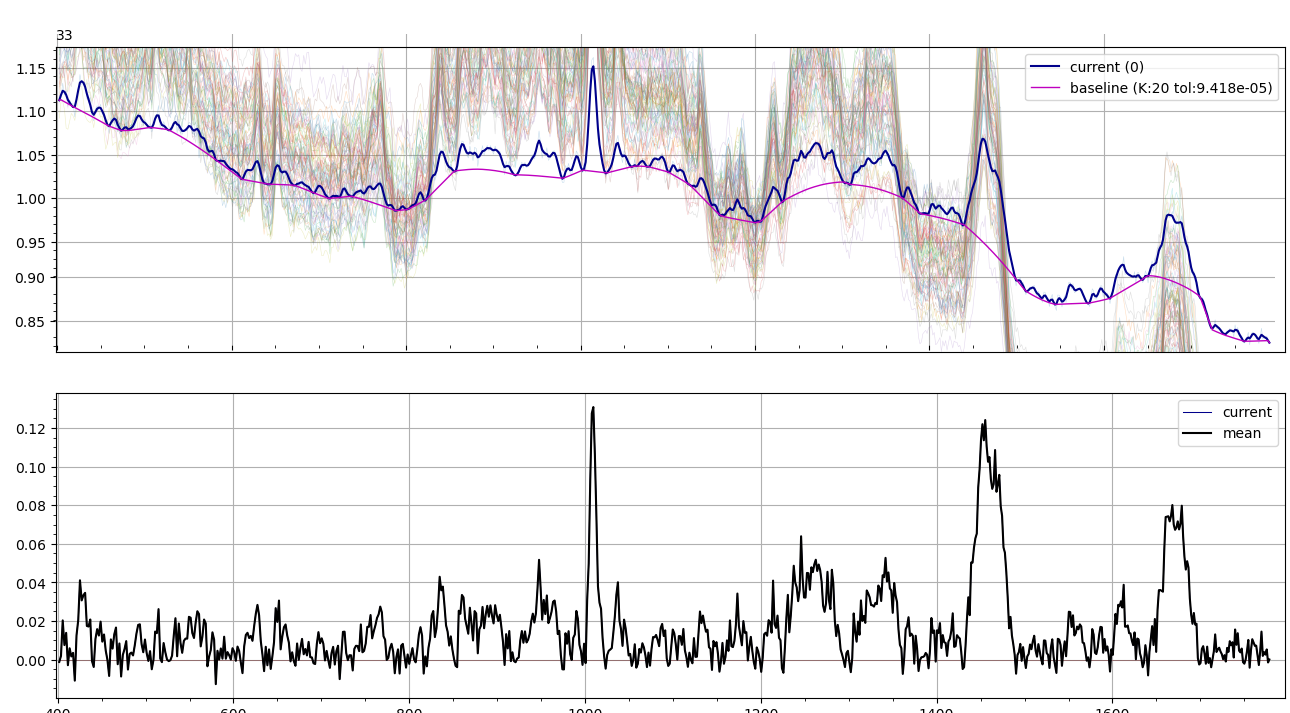

In [11]:
def subtract_baseline(x, y, tau2=1.0e3):
    bl = smooth.whittaker_smooth(
        y,
        # func=smooth.func_aspls,
        func=funcs.RStep(0.001, eps=0.001),
        # func2=funcs.SoftAbs_Sqrt(0.001).derivative_div_array,
        # func2=funcs.RStep(0.001, eps=0.001),
        func2_e=inventory.relative_abs_max,
        tau2=tau2, d=2)
    y -= bl
    y /= abs(y).mean()
    return y

In [12]:
d1.apply(subtract_baseline, inplace=True, verbose=True)

Text(value='')

In [13]:
d2.apply(subtract_baseline, inplace=True, verbose=True)

Text(value='')

In [14]:
x1 = d1.same_x()
y1 = d1.union_y()
keys1 = []
for key in d1.keys():
    keys1.extend(len(d1[key].y)*[key])
akeys1 = np.array(keys1)
print(y1.shape)
x2 = d1.same_x()
y2 = d2.union_y()
keys2 = []
for key in d2.keys():
    keys2.extend(len(d2[key].y)*[key])
akeys2 = np.array(keys2)
print(y2.shape)
np.all(x1 == x2)

z1 = np.ones(len(y1))
z2 = -np.ones(len(y2))
z = np.concatenate((z1,z2))
akeys = np.concatenate((akeys1, akeys2))
keys = keys1 + keys2
ukeys1 = np.unique(akeys1)
ukeys2 = np.unique(akeys2)
ukeys = np.unique(akeys)
print(ukeys1, ukeys2)

(230, 803)
(389, 803)
['29' '37' '39'] ['33' '34' '36' '38' '41']


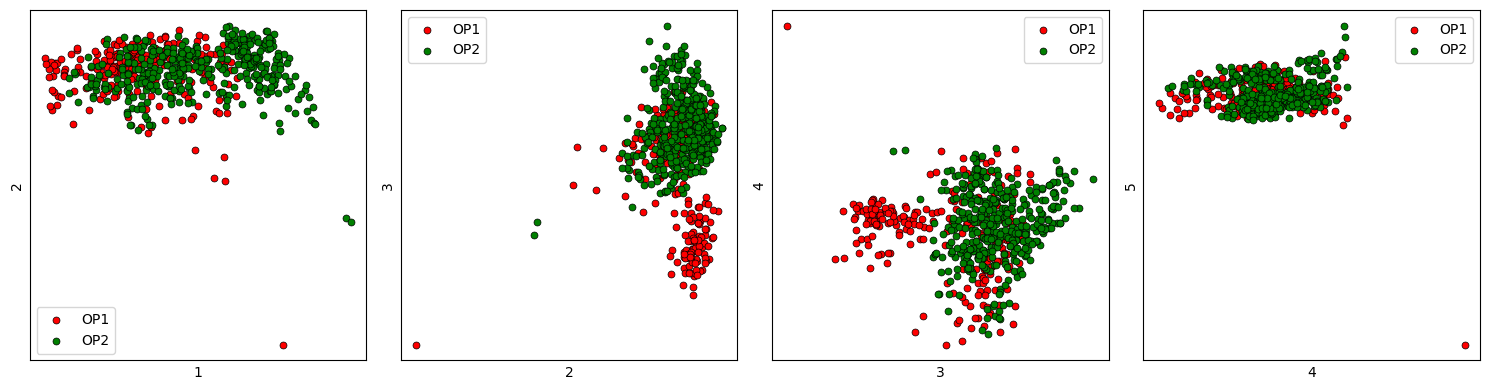

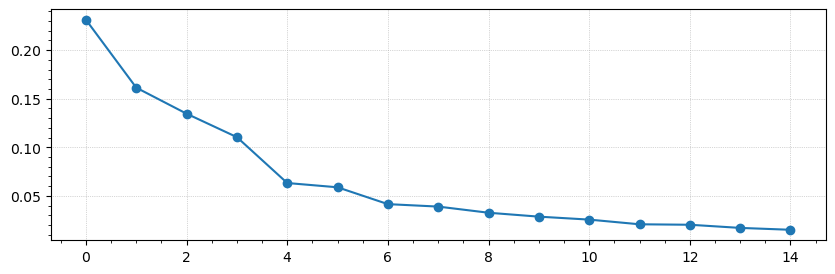

In [15]:
y = np.vstack((y1,y2))
c, As, Ls = pca.find_loc_and_pc(y, 15)
U = (y - c) @ As.T
U1 = (y1 - c) @ As.T
U2 = (y2 - c) @ As.T
plt.figure(figsize=(15,4))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.scatter(U1[:,i], U1[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="OP1")
    plt.scatter(U2[:,i], U2[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="OP2")
    plt.xlabel(str(i+1))
    plt.ylabel(str(i+2))
    plt.xticks([])
    plt.yticks([])
    plt.legend()
plt.tight_layout()
plt.legend()
plt.show()

plt.figure(figsize=(10,3))
plt.plot(Ls/Ls.sum(), marker='o')
plt.grid(ls=":", lw=0.5)
plt.minorticks_on()
plt.show()

In [16]:
import mlgrad.models as models
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss

import mlgrad.regr as regr
import mlgrad.af as af

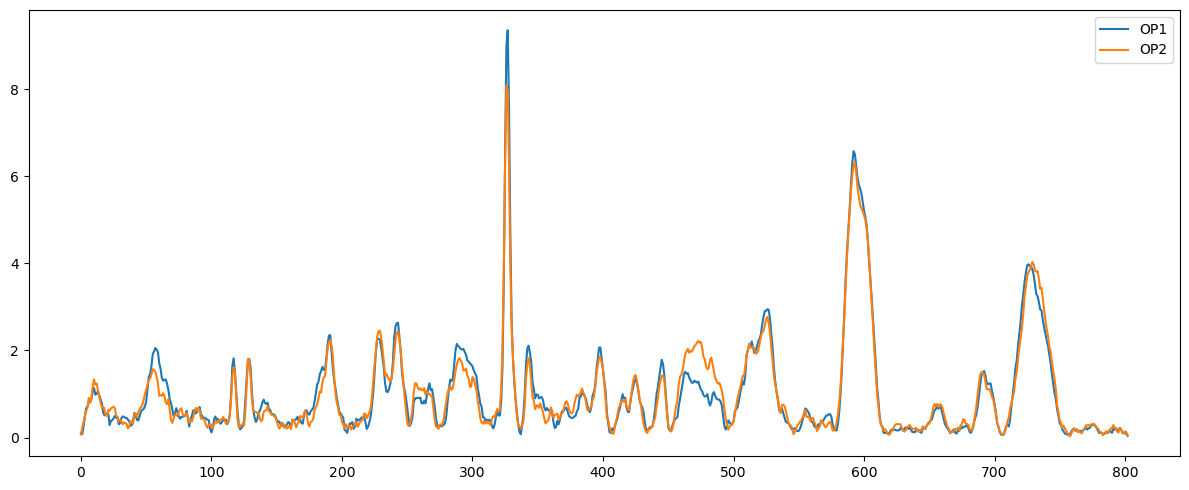

In [17]:
plt.figure(figsize=(12,5))
plt.plot(y1.mean(axis=0), label="OP1")
plt.plot(y2.mean(axis=0), label="OP2")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
w1 = np.full_like(y1, len(y2) / len(y))
w2 = np.full_like(y2, len(y1) / len(y))
w = np.concatenate((w1,w2))
lfm = models.LinearFuncModel()
for i in range(45):
    mod = models.SigmaNeuronModel(funcs.Sigmoidal(7.0), y.shape[1])
    mod.allocate()
    mod.init_param()

    alg1 = regr.regression(y, z, mod, regnorm=funcs2.AbsoluteNorm(), sample_weights=w,
                                 normalizer=gd.Masked(mod.n_param, 1.0e-4),
                                 h=0.001, tau=1.5, n_iter=1000)
    w = accuracy_score(z, np.sign(mod.evaluate(y)))
    lfm.add(mod, w)

inventory.normalize(lfm.weights.asarray())
print(accuracy_score(z, np.sign(lfm.evaluate(y))))
print(accuracy_score(z1, np.sign(lfm.evaluate(y1))))
print(accuracy_score(z2, np.sign(lfm.evaluate(y2))))

0.8303715670436187
0.8173913043478261
0.8380462724935732


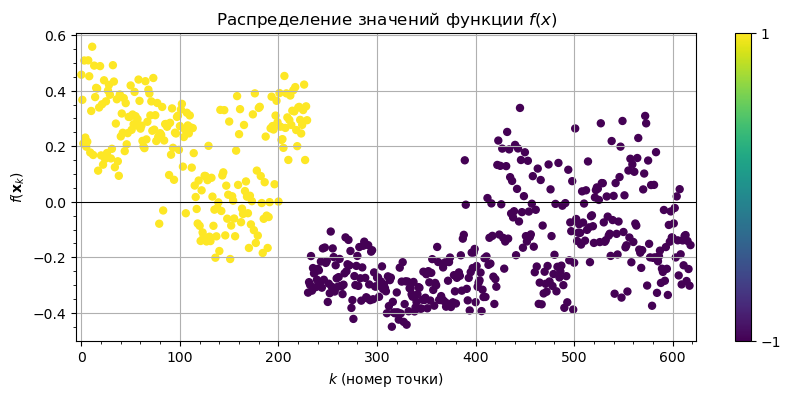

In [20]:
plt.figure(figsize=(10,4))
plots.plot_cls_function(lfm, y, z)
plt.show()

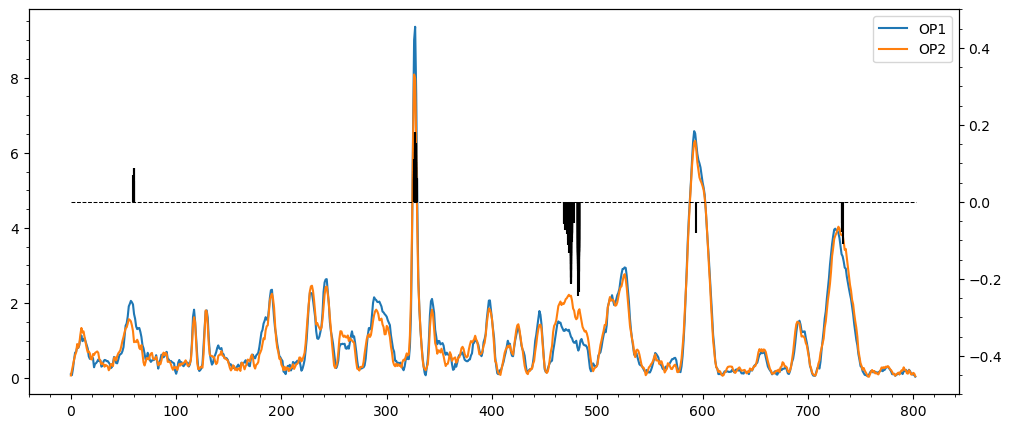

In [21]:
plt.figure(figsize=(12,5))
ax1 = plt.gca()
ax2 = plt.twinx(ax1)
ax1.plot(y1.mean(axis=0), label="OP1")
ax1.plot(y2.mean(axis=0), label="OP2")
ax1.legend()
for mod in lfm.models:
    param1 = np.asarray(mod.param[1:])
    # print(param1[0])
    param_p = param1.copy()
    param_m = param1.copy()
    param_p[param1 <= 0.005] = 0
    param_m[param1 >= -0.005] = 0
    ax2.vlines(range(y.shape[1]), 10*param_m, 10*param_p, color='k')
ax2.set_ylim(-0.5, 0.5)
ax2.hlines(0, 0, len(param1), ls='--', lw=0.75, color='k')
ax1.minorticks_on()
ax2.minorticks_on()
plt.show()

In [22]:
cm = confusion_matrix(z, np.sign(lfm.evaluate(y)))
cm = cm.astype("d")
cm[0] /= cm[0].sum()
cm[1] /= cm[1].sum()
print(cm)

[[0.838 0.162]
 [0.183 0.817]]


In [23]:
for key in d1:
    sp = d1[key]
    yy = sp.y
    ac = (np.sign(lfm.evaluate(yy)) == 1).sum() / len(yy)
    print(key, ac)

29 1.0
37 0.6923076923076923
39 0.7631578947368421


In [24]:
for key in d2:
    sp = d2[key]
    yy = sp.y
    ac = (np.sign(lfm.evaluate(yy)) == -1).sum() / len(yy)
    print(key, ac)

33 1.0
34 1.0
36 0.7435897435897436
38 0.7375
41 0.7215189873417721
